# Chapter 23: Build an Unfair Game

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** learn to read a game's rules and compute its *expected value*: write each net outcome with its sign, multiply by its probability, and add. You will see why the answer can be a number no single play ever produces, how to solve for the loss that makes a game fair, and why two games with the same average can feel very different.

The code cells are optional reading. Every result and picture is shown right below the code, so you can follow along without running anything. All amounts are in abstract units.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction as F

INK, TERRACOTTA, NAVY, TEAL, GREY, LIGHT = "#222222", "#c0563b", "#1f3a5f", "#2a8a85", "#777777", "#dddddd"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def ft(x):
    x = F(x)
    return str(x.numerator) if x.denominator == 1 else f"{x.numerator}/{x.denominator}"

def label(ax, x, v, text, color):
    """Put a label just beyond the tip of a bar."""
    ax.text(x, float(v) + (0.12 if v >= 0 else -0.12), text, ha="center", va="bottom" if v >= 0 else "top",
            color=color, fontweight="bold", bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
print("Setup done.")

Setup done.


## Demonstration 1: Weigh each outcome by its chance

**The question, in plain words:** A fair coin pays +2 on heads and costs 3 on tails. Is the game fair?

**The equations:**

$$E = (1/2)(2) + (1/2)(-3) \qquad\qquad E = -1/2$$

**What the symbols mean:**
- $E$ is the expected net value per play.
- Each outcome has a probability ($1/2$ for each face of a fair coin) and a net outcome in units: $+2$ for a gain, $-3$ for a loss.
- A *contribution* is probability times net outcome.

**Predict first:** lower the tails loss from 3 to 2. What does $E$ become?

In [2]:
gain, loss = F(2), F(-3)
half = F(1, 2)
c_heads, c_tails = half * gain, half * loss
E = c_heads + c_tails
print(f"Probabilities add to: 1/2 + 1/2 = {ft(half + half)}")
print(f"Heads contribution: (1/2)({ft(gain)}) = {ft(c_heads)}")
print(f"Tails contribution: (1/2)({ft(loss)}) = {ft(c_tails)}")
print(f"E = {ft(c_heads)} + ({ft(c_tails)}) = {ft(E)} unit per play")
print()
print("Other menu values (tails loss 3, 2, 1):")
for L in (3, 2, 1):
    ch, ct = half * 2, half * (-L)
    print(f"loss {L}: (1/2)(2) + (1/2)({-L}) = {ft(ch)} + ({ft(ct)}) = {ft(ch + ct)}")

Probabilities add to: 1/2 + 1/2 = 1
Heads contribution: (1/2)(2) = 1
Tails contribution: (1/2)(-3) = -3/2
E = 1 + (-3/2) = -1/2 unit per play

Other menu values (tails loss 3, 2, 1):
loss 3: (1/2)(2) + (1/2)(-3) = 1 + (-3/2) = -1/2
loss 2: (1/2)(2) + (1/2)(-2) = 1 + (-1) = 0
loss 1: (1/2)(2) + (1/2)(-1) = 1 + (-1/2) = 1/2


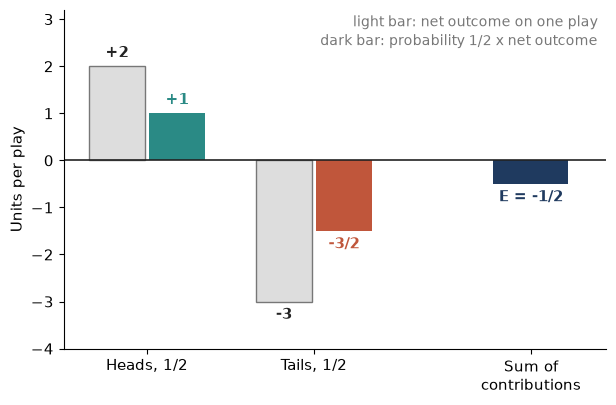

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.bar([-0.18, 0.82], [float(gain), float(loss)], width=0.34, color=LIGHT, edgecolor=GREY)
ax.bar([0.18, 1.18], [float(c_heads), float(c_tails)], width=0.34, color=[TEAL, TERRACOTTA])
ax.bar([2.3], [float(E)], width=0.45, color=NAVY)
label(ax, -0.18, gain, "+2", INK); label(ax, 0.82, loss, "-3", INK)
label(ax, 0.18, c_heads, "+1", TEAL); label(ax, 1.18, c_tails, ft(c_tails), TERRACOTTA)
label(ax, 2.3, E, "E = " + ft(E), NAVY)
ax.axhline(0, color=INK, linewidth=1.2)
ax.text(2.7, 2.85, "light bar: net outcome on one play", ha="right", fontsize=10, color=GREY)
ax.text(2.7, 2.45, "dark bar: probability 1/2 x net outcome", ha="right", fontsize=10, color=GREY)
ax.set_xticks([0, 1, 2.3]); ax.set_xticklabels(["Heads, 1/2", "Tails, 1/2", "Sum of\ncontributions"])
ax.set_xlim(-0.5, 2.75); ax.set_ylim(-4.0, 3.2); ax.set_ylabel("Units per play")
plt.show()

**What this shows:** each light bar is what one play can pay. Each dark bar is that payment scaled by its probability. The dark bars add to $E = -1/2$, which is not on the list of one-play results (you only ever win 2 or lose 3). It is a weighted average, and it says this game sits on the loss side for the player.

**Where it stops working:** the model assumes an ideal fair coin and net outcomes that already include every cost of one play. $E$ describes the long-run average, not the next play: a short run can land anywhere.

## Demonstration 2: An average no play can produce

**The question, in plain words:** A gain of 4 with chance $1/4$ and a loss of 2 with chance $3/4$: where does $E$ land?

**The equation:**

$$E = \tfrac14(4) + \tfrac34(-2) = 1 - \tfrac32 = -\tfrac12$$

**What the symbols mean:**
- Think of four places: one gain place and three loss places. Those are the weights $1/4$ and $3/4$.
- A *fee* is a charge on every play, so it comes off every outcome.

**Predict first:** charge a fee of 1 unit on every play. How far does $E$ move?

In [4]:
for fee in (0, 1, 2):
    g, l = F(4 - fee), F(-2 - fee)
    entries = [g, l, l, l]
    E2 = F(1, 4) * g + F(3, 4) * l
    total = sum(entries)
    print(f"Fee {fee}: outcomes {ft(g)} (chance 1/4) and {ft(l)} (chance 3/4)")
    print(f"   E = (1/4)({ft(g)}) + (3/4)({ft(l)}) = {ft(F(1, 4) * g)} + ({ft(F(3, 4) * l)}) = {ft(E2)}")
    print(f"   template total: {ft(g)} + 3 x ({ft(l)}) = {ft(total)};  {ft(total)}/4 = {ft(E2)}")
    print(f"   bound check: {ft(l)} < {ft(E2)} < {ft(g)} is {l < E2 < g}")

Fee 0: outcomes 4 (chance 1/4) and -2 (chance 3/4)
   E = (1/4)(4) + (3/4)(-2) = 1 + (-3/2) = -1/2
   template total: 4 + 3 x (-2) = -2;  -2/4 = -1/2
   bound check: -2 < -1/2 < 4 is True
Fee 1: outcomes 3 (chance 1/4) and -3 (chance 3/4)
   E = (1/4)(3) + (3/4)(-3) = 3/4 + (-9/4) = -3/2
   template total: 3 + 3 x (-3) = -6;  -6/4 = -3/2
   bound check: -3 < -3/2 < 3 is True
Fee 2: outcomes 2 (chance 1/4) and -4 (chance 3/4)
   E = (1/4)(2) + (3/4)(-4) = 1/2 + (-3) = -5/2
   template total: 2 + 3 x (-4) = -10;  -10/4 = -5/2
   bound check: -4 < -5/2 < 2 is True


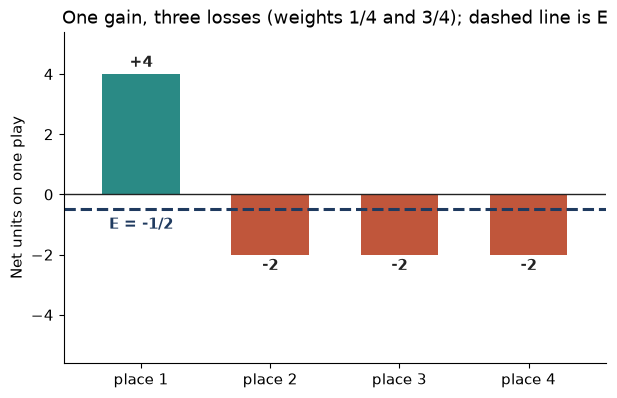

In [5]:
fee = 0
g, l = F(4 - fee), F(-2 - fee)
entries = [g, l, l, l]
E2 = F(1, 4) * g + F(3, 4) * l
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.bar(range(1, 5), [float(v) for v in entries], width=0.6, color=[TEAL] + [TERRACOTTA] * 3)
for k, v in enumerate(entries, start=1):
    label(ax, k, v, ("+" if v > 0 else "") + ft(v), INK)
ax.axhline(float(E2), color=NAVY, linewidth=2.2, linestyle="dashed")
ax.text(1.0, float(E2) - 0.25, f"E = {ft(E2)}", ha="center", va="top", color=NAVY, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
ax.axhline(0, color=INK, linewidth=1)
ax.set_xticks(range(1, 5)); ax.set_xticklabels(["place 1", "place 2", "place 3", "place 4"])
ax.set_xlim(0.4, 4.6); ax.set_ylim(-5.6, 5.4)
ax.set_ylabel("Net units on one play")
ax.set_title("One gain, three losses (weights 1/4 and 3/4); dashed line is E")
plt.show()

**What this shows:** the template's total divided by 4 is the probability-weighted average: $(4 - 2 - 2 - 2)/4 = -2/4 = -1/2$. A fee on every play lowers each bar by the fee, so the average line drops by exactly the fee: with a fee of 1, $E = -3/2$; with a fee of 2, $E = -5/2$. A computed expectation must always sit between the smallest and largest outcome, which makes a handy bound check.

**Where it stops working:** the probabilities $1/4$ and $3/4$ are stated, and the template shows the weights only; it does not promise that any four real plays contain exactly one gain. A fee on only one branch would need its own row.

## Demonstration 3: Solve for the fair loss

**The question, in plain words:** A game gains 9 with chance $1/4$. What loss on the other branch makes it fair?

**The equations:**

$$(1/4)(9) + (3/4)(-x) = 0 \qquad\qquad 9 - 3x = 0$$

**What the symbols mean:**
- $x$ is the size of the loss, so the loss branch's net outcome is $-x$.
- *Fair* here means the expected net value $E$ equals 0.
- Multiplying the whole equation by 4 clears the fractions.

**Predict first:** try a loss of 2. Is the expected value above zero or below it?

In [6]:
x = 3
up = F(1, 4) * 9
down = F(3, 4) * (-x)
E3 = up + down
print(f"Gain branch: (1/4)(9) = {ft(up)}")
print(f"Loss branch (x = {x}): (3/4)({-x}) = {ft(down)}")
print(f"E = {ft(up)} + ({ft(down)}) = {ft(E3)}")
print(f"Times 4: 9 - 3({x}) = {9 - 3 * x}")
print("Solve 9 - 3x = 0:  3x = 9,  x = 3")
print()
print("Other menu values:")
for xx in (1, 2, 3, 4):
    e = F(1, 4) * 9 + F(3, 4) * (-xx)
    verdict = "fair" if e == 0 else ("E above 0, loss too small" if e > 0 else "E below 0, loss too large")
    print(f"x = {xx}: 9/4 + ({ft(F(3, 4) * -xx)}) = {ft(e)}   (9 - 3x = {9 - 3 * xx}, {verdict})")

Gain branch: (1/4)(9) = 9/4
Loss branch (x = 3): (3/4)(-3) = -9/4
E = 9/4 + (-9/4) = 0
Times 4: 9 - 3(3) = 0
Solve 9 - 3x = 0:  3x = 9,  x = 3

Other menu values:
x = 1: 9/4 + (-3/4) = 3/2   (9 - 3x = 6, E above 0, loss too small)
x = 2: 9/4 + (-3/2) = 3/4   (9 - 3x = 3, E above 0, loss too small)
x = 3: 9/4 + (-9/4) = 0   (9 - 3x = 0, fair)
x = 4: 9/4 + (-3) = -3/4   (9 - 3x = -3, E below 0, loss too large)


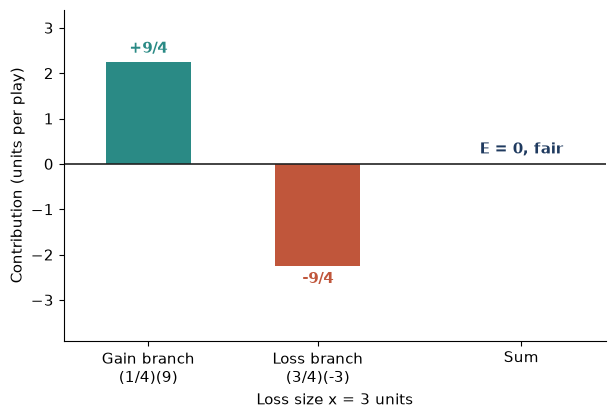

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.bar([0], [float(up)], width=0.5, color=TEAL)
ax.bar([1], [float(down)], width=0.5, color=TERRACOTTA)
ax.bar([2.2], [float(E3)], width=0.5, color=NAVY)
label(ax, 0, up, "+" + ft(up), TEAL)
label(ax, 1, down, ft(down), TERRACOTTA)
ax.text(2.2, 0.15, "E = 0, fair", ha="center", va="bottom", color=NAVY, fontweight="bold")
ax.axhline(0, color=INK, linewidth=1.2)
ax.set_xticks([0, 1, 2.2]); ax.set_xticklabels(["Gain branch\n(1/4)(9)", f"Loss branch\n(3/4)({-x})", "Sum"])
ax.set_xlim(-0.5, 2.7); ax.set_ylim(-3.9, 3.4)
ax.set_xlabel(f"Loss size x = {x} units"); ax.set_ylabel("Contribution (units per play)")
plt.show()

**What this shows:** the gain branch always contributes $9/4$. The loss branch contributes $3/4$ of $-x$. Only when the two bars have the same length, one up and one down, does the sum vanish. That happens at $x = 3$. Instead of guessing, set the expected value to zero and solve.

**Where it stops working:** "fair" here means zero expected net value. It says nothing about any single play, and it does not price any real game or product. The stated probabilities are part of the model.

## Demonstration 4: Same center, different spread

**The question, in plain words:** Two loss models both have $E = -1$. Are they the same experience?

**The equations:**

$$E = 1(-1) = -1 \qquad\qquad E = (1/2)(0) + (1/2)(-2) = -1$$

**What the symbols mean:**
- Model A always loses 1 unit.
- Model B has two net outcomes, each with probability $1/2$, the same distance above and below $-1$.
- The *range* is the largest outcome minus the smallest.

**Predict first:** set Model B's spread to 0. Can you still tell the two models apart?

In [8]:
print("Model A: E = 1(-1) = -1, range 0")
spread = 1
lo, hi = -1 - spread, -1 + spread
eB = F(1, 2) * hi + F(1, 2) * lo
print(f"Model B (spread {spread}): outcomes {lo} and {hi}, each 1/2")
print(f"E = (1/2)({hi}) + (1/2)({lo}) = {ft(F(1, 2) * hi)} + ({ft(F(1, 2) * lo)}) = {ft(eB)}")
print(f"Range: {hi} - ({lo}) = {hi - lo}")
print()
print("Other menu values:")
for s in (0, 1, 2, 4):
    l_, h_ = -1 - s, -1 + s
    e_ = F(1, 2) * h_ + F(1, 2) * l_
    print(f"spread {s}: outcomes {l_} and {h_}; E = (1/2)({h_}) + (1/2)({l_}) = {ft(e_)}; range {h_} - ({l_}) = {h_ - l_}")

Model A: E = 1(-1) = -1, range 0
Model B (spread 1): outcomes -2 and 0, each 1/2
E = (1/2)(0) + (1/2)(-2) = 0 + (-1) = -1
Range: 0 - (-2) = 2

Other menu values:
spread 0: outcomes -1 and -1; E = (1/2)(-1) + (1/2)(-1) = -1; range -1 - (-1) = 0
spread 1: outcomes -2 and 0; E = (1/2)(0) + (1/2)(-2) = -1; range 0 - (-2) = 2
spread 2: outcomes -3 and 1; E = (1/2)(1) + (1/2)(-3) = -1; range 1 - (-3) = 4
spread 4: outcomes -5 and 3; E = (1/2)(3) + (1/2)(-5) = -1; range 3 - (-5) = 8


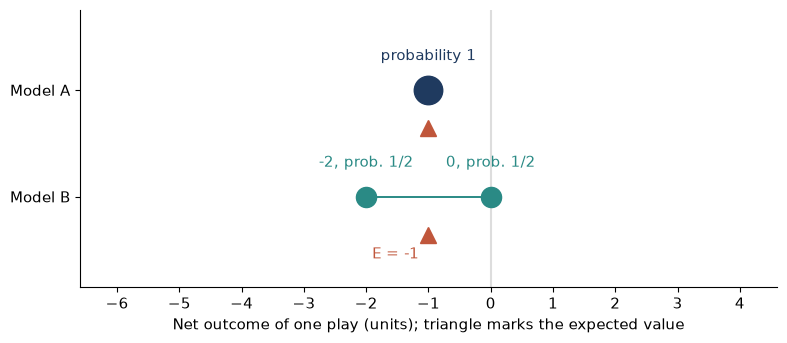

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter([-1], [1], s=420, color=NAVY, zorder=3)
ax.text(-1, 1.28, "probability 1", ha="center", color=NAVY)
ax.scatter([lo, hi], [0, 0], s=210, color=TEAL, zorder=3)
ax.plot([lo, hi], [0, 0], color=TEAL, linewidth=1.4)
for v in (lo, hi):
    ax.text(v, 0.28, f"{v}, prob. 1/2", ha="center", color=TEAL)
for y in (1, 0):
    ax.plot([-1], [y - 0.36], marker="^", markersize=11, color=TERRACOTTA, zorder=3)
ax.text(-1.15, -0.58, "E = -1", ha="right", color=TERRACOTTA)
ax.axvline(0, color=LIGHT, zorder=1)
ax.set_yticks([0, 1]); ax.set_yticklabels(["Model B", "Model A"])
ax.set_xlim(-6.6, 4.6); ax.set_ylim(-0.85, 1.75); ax.set_xticks(range(-6, 5))
ax.set_xlabel("Net outcome of one play (units); triangle marks the expected value")
plt.show()

**What this shows:** moving Model B's two outcomes apart by equal amounts keeps their average at $-1$, so the triangles stay put. What changes is how far a single play can land from the center: Model A always gives $-1$, while Model B (spread 1) lands on $-2$ or $0$.

**Where it stops working:** expected value compares centers only. Choosing between the models would need preferences and facts this model does not contain. When two choices have the same expected value, list their possible outcomes too. The average answers one question and leaves the spread question on the desk.

## Practice

**1.** If heads paid +4 and tails cost 3 on a fair coin, what would the expected net value be?

<details><summary>Show answer</summary>

$E = (1/2)(4) + (1/2)(-3) = 2 - 3/2 = 1/2$ unit per play.

</details>

**2.** The 1/4 and 3/4 game (gain 4, loss 2) now charges a fee of 2 units on every play. What is $E$, and does it pass the bound check?

<details><summary>Show answer</summary>

Outcomes: $4 - 2 = 2$ and $-2 - 2 = -4$.
$E = (1/4)(2) + (3/4)(-4) = 1/2 - 3 = -5/2$.
Bound check: $-4 < -5/2 < 2$, so it passes.

</details>

**3.** If the gain were 6 with chance 1/4, what loss makes the game fair?

<details><summary>Show answer</summary>

$(1/4)(6) + (3/4)(-x) = 0$.
Multiply by 4: $6 - 3x = 0$.
So $3x = 6$ and $x = 2$ units.

</details>